## Ćwiczenie 7 – Operacje Morfologiczne na Obrazie Medycznym

### Cel zajęć
Przejście od surowego, zaszumionego obrazu medycznego (fantom tomograficzny Shepp-Logana) do czystej, pełnej maski narządu przy użyciu `scikit-image` oraz `scipy`.

---

### Krok 1: Wczytanie obrazu medycznego i symulacja warunków klinicznych
Wczytujemy fantom tomograficzny `shepp_logan_phantom()`, wycinamy intersującą strukturę (np. komory mózgu) i dodajemy szum Gaussa.

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


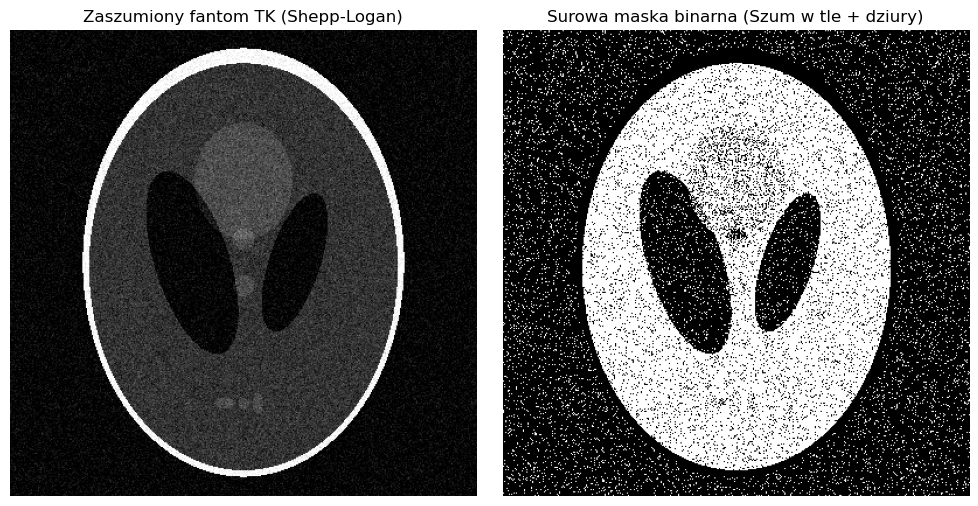

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, morphology, util
from scipy import ndimage

# 1. Wczytanie fantomu medycznego TK
phantom = data.shepp_logan_phantom()

# 2. Dodanie szumu (symulacja niskiego dawkowania RTG/TK)
noisy_phantom = util.random_noise(phantom, mode='gaussian', var=0.005)

# 3. Proste progowanie (binaryzacja) – otrzymujemy 'brudną' maskę binarne z ubytkami
raw_mask = (noisy_phantom > 0.1) & (noisy_phantom < 0.35)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(noisy_phantom, cmap='gray')
axes[0].set_title('Zaszumiony fantom TK (Shepp-Logan)')
axes[1].imshow(raw_mask, cmap='gray')
axes[1].set_title('Surowa maska binarna (Szum w tle + dziury)')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

### Krok 2: Badanie wpływu rozmiaru elementu strukturalnego
Sprawdź, jak promien elementu strukturalnego (`disk(r)`) wpływa na jakość usuwania szumu i ryzyko zniekształcenia narządu?

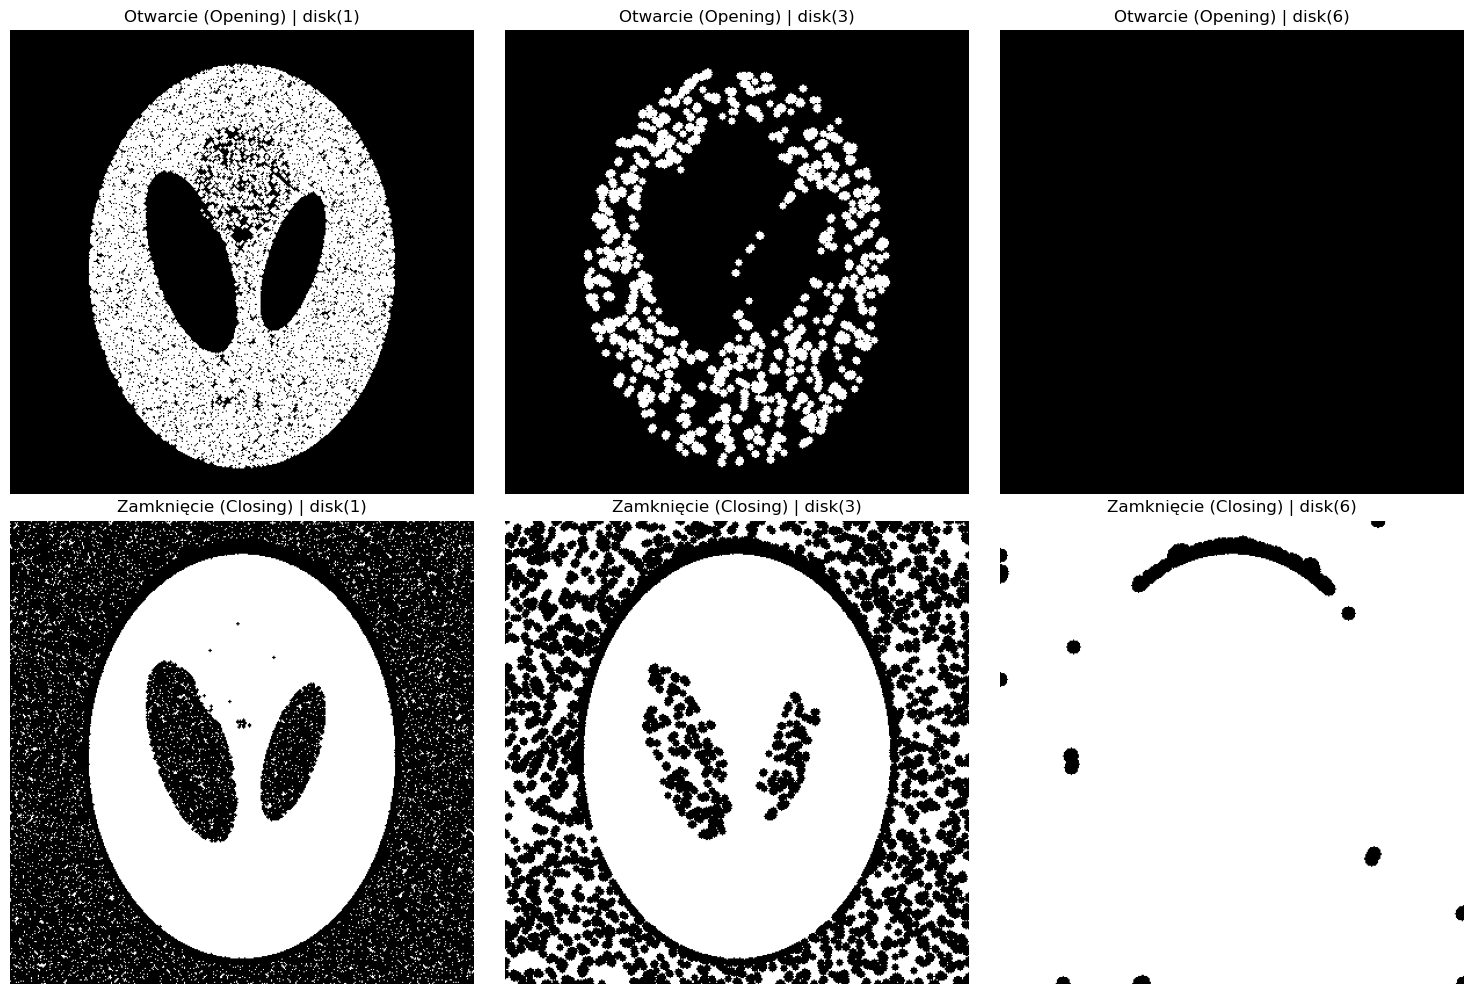

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for idx, r in enumerate([1, 3, 6]):
    selem = morphology.disk(r)
    opened = morphology.opening(raw_mask, selem)
    closed = morphology.closing(raw_mask, selem)
    
    axes[0, idx].imshow(opened, cmap='gray')
    axes[0, idx].set_title(f'Otwarcie (Opening) | disk({r})')
    
    axes[1, idx].imshow(closed, cmap='gray')
    axes[1, idx].set_title(f'Zamknięcie (Closing) | disk({r})')

for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()
plt.show()

### Krok 3: Sekwencja (pipeline) oczyszczanie + wypełnianie ubytków
Łączymy Otwarcie (usunięcie szumu w tle), Zamknięcie (sklejenie brzegów) oraz `scipy.ndimage.binary_fill_holes()` (zalanie wnętrza).

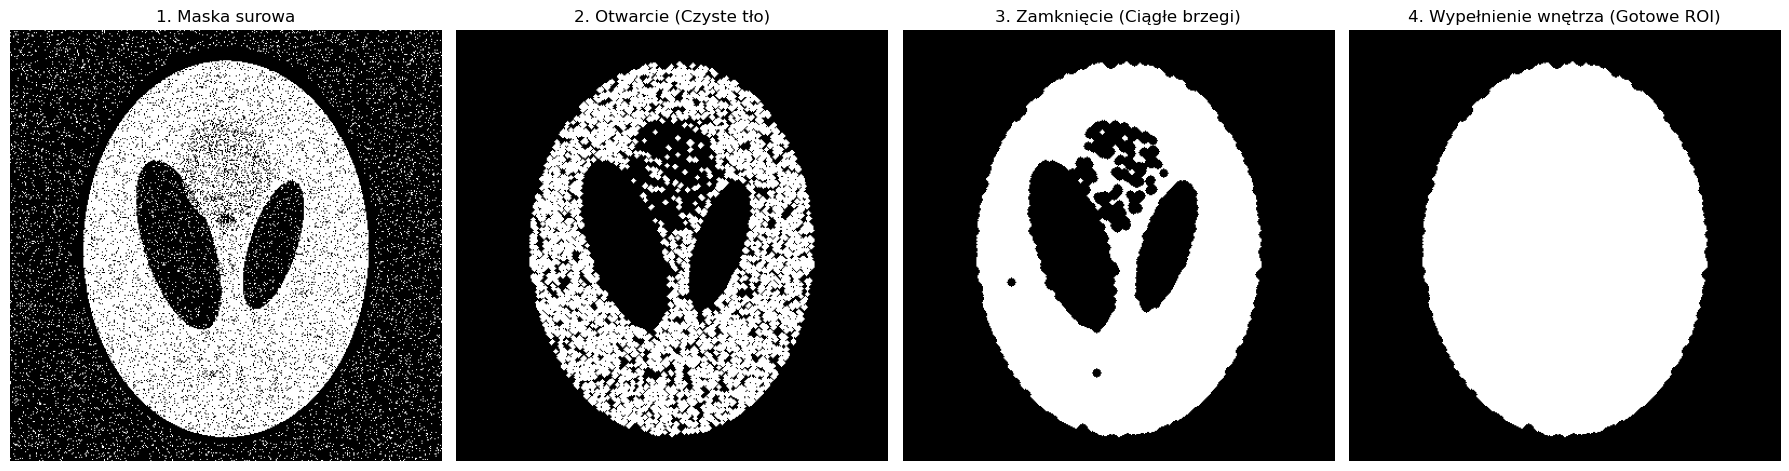

In [11]:
# 1. Usunięcie drobnokomórkowego szumu z tła (Otwarcie r=2)
clean_bg = morphology.opening(raw_mask, morphology.disk(2))

# 2. Sklejenie poszarpanych brzegów struktury (Zamknięcie r=4)
closed_structure = morphology.closing(clean_bg, morphology.disk(4))

# 3. Zalanie otworów wewnątrz narządu (Scipy binary_fill_holes)
final_roi = ndimage.binary_fill_holes(closed_structure)

# Wizualizacja etapów
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(raw_mask, cmap='gray'); axes[0].set_title('1. Maska surowa')
axes[1].imshow(clean_bg, cmap='gray'); axes[1].set_title('2. Otwarcie (Czyste tło)')
axes[2].imshow(closed_structure, cmap='gray'); axes[2].set_title('3. Zamknięcie (Ciągłe brzegi)')
axes[3].imshow(final_roi, cmap='gray'); axes[3].set_title('4. Wypełnienie wnętrza (Gotowe ROI)')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

### Krok 4: Analiza ilościowa (pomiar pola powierzchni)
Obliczamy pole powierzchni uzyskanej struktury w pikselach oraz wyznaczamy kontur nałożony na oryginalny obraz tomograficzny.

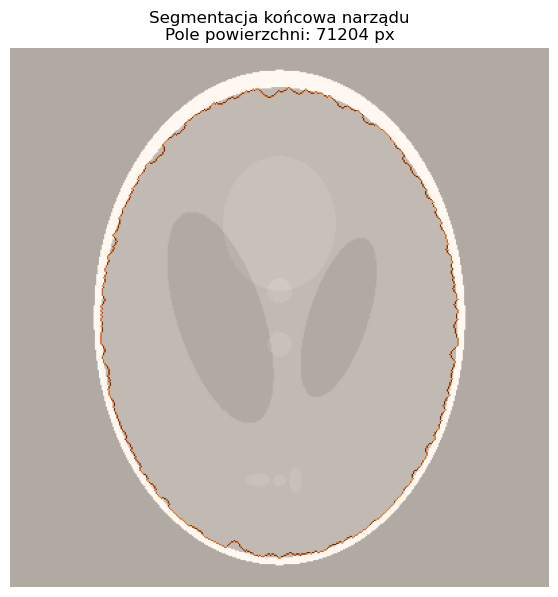

In [14]:
# Obliczenie powierzchni (liczba białych pikseli)
area_pixels = np.sum(final_roi)

# Wyznaczenie samych krawędzi powstałej maski do nałożenia na obraz źródłowy
roi_contour = morphology.dilation(final_roi) ^ final_roi #XOR 

plt.figure(figsize=(7, 7))
plt.imshow(phantom, cmap='gray')
plt.imshow(roi_contour, cmap='Oranges', alpha=0.7)  # Nakładamy pomarańczowy obrys
plt.title(f'Segmentacja końcowa narządu\nPole powierzchni: {area_pixels} px')
plt.axis('off')
plt.show()